# Numerical Data
- modeling data
    - descriptive models: pattern evaluation
        - descriptive statics, e.g., central tendencies, dispersion, correlation, covar
        - unsupervised ML techniques: clustering, dimensionality reduction, eg. pca
    - predictive models: 
        - inferential statistics: t-tests, ANoVA, etc.
        - supervised ML: -> classification, regression, association rule mining for recommeders

In [2]:
import torch
import torch.utils.data as data_utils
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import hiddenlayer as hl

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline

In [39]:
df_head = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos\datasets\headbrain.csv")
df_head.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Gender,237.0,1.434599,0.496753,1.0,1.0,1.0,2.0,2.0
Age Range,237.0,1.535865,0.499768,1.0,1.0,2.0,2.0,2.0
Head Size(cm^3),237.0,3633.991561,365.261422,2720.0,3389.0,3614.0,3876.0,4747.0
Brain Weight(grams),237.0,1282.873418,120.340446,955.0,1207.0,1280.0,1350.0,1635.0


In [40]:
df_head = pd.get_dummies(df_head, columns=['Gender', 'Age Range'], drop_first=True).astype(int)
df_head = df_head.rename(columns={
    'Head Size(cm^3)':'Head_size', 
    'Brain Weight(grams)':'Brain_weight', 
    'Gender_2':'Gender', 
    'Age Range_2':'Age_range'
    })
df_head.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Head_size,237.0,3633.991561,365.261422,2720.0,3389.0,3614.0,3876.0,4747.0
Brain_weight,237.0,1282.873418,120.340446,955.0,1207.0,1280.0,1350.0,1635.0
Gender,237.0,0.434599,0.496753,0.0,0.0,0.0,1.0,1.0
Age_range,237.0,0.535865,0.499768,0.0,0.0,1.0,1.0,1.0


In [41]:
# traditional ML regression
features = df_head.drop(columns=['Brain_weight'])
target = df_head['Brain_weight']
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

pipe.fit(X_train, y_train)

y_pred = pipe.predict(X_test)

print('R score:', r2_score(y_test, y_pred))

R score: 0.6781882908746382


In [42]:
# neural network
features = df_head['Head_size']
target = df_head['Brain_weight']
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2)

X_train_ts = torch.tensor(X_train.values.reshape(-1,1), dtype=torch.float)
X_test_ts = torch.tensor(X_test.values.reshape(-1,1), dtype=torch.float)
y_train_ts = torch.tensor(y_train.values.reshape(-1,1), dtype=torch.float)
y_test_ts = torch.tensor(y_test.values.reshape(-1,1), dtype=torch.float)

In [43]:
input_layer = 1
hiddel_layer = 12
output_layer = 1

loss_fn = torch.nn.MSELoss(reduction='sum')

model = torch.nn.Sequential(torch.nn.Linear(input_layer, hiddel_layer),
                            torch.nn.ReLU(),
                            torch.nn.Linear(hiddel_layer, output_layer))

learning_rate = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for i in range(2000):
    y_pred = model(X_train_ts)
    loss = loss_fn(y_pred, y_train_ts)
    print('Iteration no: %s and Loss: %s' %(i, loss.item()))

    model.zero_grad()
    loss.backward()
    optimizer.step()

Iteration no: 0 and Loss: 297373568.0
Iteration no: 1 and Loss: 296794336.0
Iteration no: 2 and Loss: 296215616.0


Iteration no: 3 and Loss: 295637248.0
Iteration no: 4 and Loss: 295059424.0
Iteration no: 5 and Loss: 294481984.0
Iteration no: 6 and Loss: 293905056.0
Iteration no: 7 and Loss: 293328608.0
Iteration no: 8 and Loss: 292752640.0
Iteration no: 9 and Loss: 292177184.0
Iteration no: 10 and Loss: 291602176.0
Iteration no: 11 and Loss: 291027744.0
Iteration no: 12 and Loss: 290453792.0
Iteration no: 13 and Loss: 289880352.0
Iteration no: 14 and Loss: 289307424.0
Iteration no: 15 and Loss: 288735104.0
Iteration no: 16 and Loss: 288163264.0
Iteration no: 17 and Loss: 287592032.0
Iteration no: 18 and Loss: 287021280.0
Iteration no: 19 and Loss: 286451136.0
Iteration no: 20 and Loss: 285881504.0
Iteration no: 21 and Loss: 285312480.0
Iteration no: 22 and Loss: 284744000.0
Iteration no: 23 and Loss: 284176096.0
Iteration no: 24 and Loss: 283608832.0
Iteration no: 25 and Loss: 283042112.0
Iteration no: 26 and Loss: 282476000.0
Iteration no: 27 and Loss: 281910464.0
Iteration no: 28 and Loss: 28134

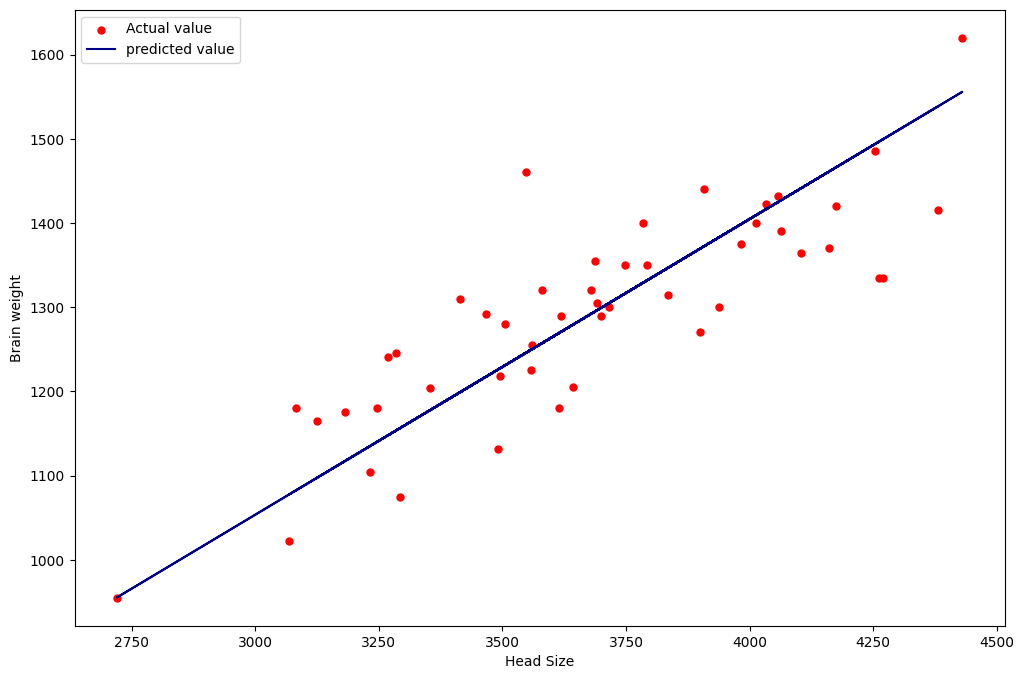

In [44]:
model.eval()

with torch.no_grad():
    y_pred_ts = model(X_test_ts)

y_pred = y_pred_ts.detach().numpy()

plt.figure(figsize=(12,8))
plt.scatter(X_test, y_test, s=25, c='red', label='Actual value')
plt.plot(X_test, y_pred, label='predicted value', c='darkblue')
plt.xlabel('Head Size')
plt.ylabel('Brain weight')
plt.legend()
plt.show()

In [45]:
r2_score(y_test, y_pred)

0.6340234279632568

# Exercise - Regression Model

In [25]:
# Diamonds price prediction
df_diamonds = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos\datasets\diamonds.csv",
                          index_col=[0])
df_diamonds.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [26]:
#ML approach
df_diamonds[['cut', 'color', 'clarity']].describe()

,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


In [27]:
# ordinal encoding
color_dict = {'D':0, 'E':1, 'F':2, 'G':3, 'H':4, 'I':5, 'J':6}
df_diamonds.replace({'color':color_dict}, inplace=True)
cut_dict = {'Fair':0, 'Good':1, 'Very Good':2, 'Premium':3, 'Ideal':4}
df_diamonds.replace({'cut':cut_dict}, inplace=True)
clarity_dict = {'I1':0, 'SI2':1, 'SI1':2, 'VS2':3, 'VS1':4, 'VVS2':5, 'VVS1':6, 'IF':7}
df_diamonds.replace({'clarity':clarity_dict}, inplace=True)

C:\Users\Andrew\AppData\Local\Temp\ipykernel_14152\3545624648.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_diamonds.replace({'color':color_dict}, inplace=True)
C:\Users\Andrew\AppData\Local\Temp\ipykernel_14152\3545624648.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_diamonds.replace({'cut':cut_dict}, inplace=True)
C:\Users\Andrew\AppData\Local\Temp\ipykernel_14152\3545624648.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, 

r2 score: 0.906977399363575


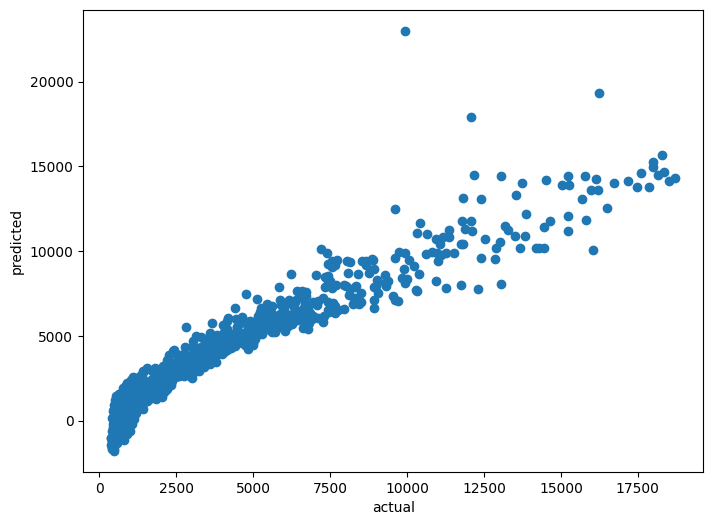

In [28]:
df_diamonds=df_diamonds.sample(5000, replace=False)
X = df_diamonds.drop(columns='price', axis=1)
Y = df_diamonds['price']

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('estimator', LinearRegression())
])

pipe.fit(X_train, y_train)

y_pred = pipe.predict(X_test)
print('r2 score:', r2_score(y_test, y_pred))

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred)
plt.xlabel('actual')
plt.ylabel('predicted')
plt.show()

In [31]:
# neural network
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test) 

X_train_ts = torch.tensor(X_train, dtype=torch.float)
X_test_ts = torch.tensor(X_test, dtype=torch.float)
y_train_ts = torch.tensor(y_train.values, dtype=torch.float).view(-1, 1)
y_test_ts = torch.tensor(y_test.values, dtype=torch.float).view(-1, 1)
y_train_ts.shape, y_test_ts.shape

(torch.Size([4000, 1]), torch.Size([1000, 1]))

In [32]:
# batch training dataset
train_dataset = data_utils.TensorDataset(X_train_ts, y_train_ts)
train_loader = data_utils.DataLoader(train_dataset, batch_size=500, shuffle=True)
len(train_loader)

8

In [43]:
# design neural network
input_layer = X_train_ts.shape[1] # no. of columns in the feature dataset
output_layer = 1
hiddel_layer = 12
loss_fn = torch.nn.MSELoss()
learning_rate = 0.01

model = torch.nn.Sequential(torch.nn.Linear(input_layer, hiddel_layer),
                            torch.nn.ReLU(),
                            torch.nn.Dropout(p=0.3),
                            torch.nn.Linear(hiddel_layer, output_layer))

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [44]:
# training
total_steps = len(train_loader)
num_epochs = 1000

for epoch in range(num_epochs+1):
    for i, (features, target) in enumerate(train_loader):
        output = model(features)
        loss = loss_fn(output, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 200 == 0:
            print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}'
                  .format(epoch+1, num_epochs, i+1, total_steps, loss.item()), flush=True)

Epoch [1/1000], Step [1/8], Loss: 25709194.0000
Epoch [1/1000], Step [2/8], Loss: 31634494.0000
Epoch [1/1000], Step [3/8], Loss: 30744830.0000
Epoch [1/1000], Step [4/8], Loss: 29241486.0000
Epoch [1/1000], Step [5/8], Loss: 28566274.0000
Epoch [1/1000], Step [6/8], Loss: 30803820.0000


Epoch [1/1000], Step [7/8], Loss: 31515312.0000
Epoch [1/1000], Step [8/8], Loss: 28420494.0000
Epoch [201/1000], Step [1/8], Loss: 3099812.2500
Epoch [201/1000], Step [2/8], Loss: 2167870.0000
Epoch [201/1000], Step [3/8], Loss: 2155283.7500
Epoch [201/1000], Step [4/8], Loss: 1996072.5000
Epoch [201/1000], Step [5/8], Loss: 2300958.2500
Epoch [201/1000], Step [6/8], Loss: 2215523.7500
Epoch [201/1000], Step [7/8], Loss: 2291138.0000
Epoch [201/1000], Step [8/8], Loss: 1822611.3750
Epoch [401/1000], Step [1/8], Loss: 1752202.8750
Epoch [401/1000], Step [2/8], Loss: 2224786.0000
Epoch [401/1000], Step [3/8], Loss: 2187733.7500
Epoch [401/1000], Step [4/8], Loss: 2643832.2500
Epoch [401/1000], Step [5/8], Loss: 2055532.2500
Epoch [401/1000], Step [6/8], Loss: 2117763.7500
Epoch [401/1000], Step [7/8], Loss: 2225621.7500
Epoch [401/1000], Step [8/8], Loss: 2191127.7500
Epoch [601/1000], Step [1/8], Loss: 1823722.8750
Epoch [601/1000], Step [2/8], Loss: 2245040.7500
Epoch [601/1000], Step

In [ ]:
# forward pass
model.eval()

with torch.no_grad():
    y_pred_ts = model(X_test_ts)

y_pred = y_pred_ts.detach().numpy()

print(y_pred.shape)
print('r2 score:', r2_score(y_test, y_pred))

compare_df = pd.DataFrame(
                    {'Actual price': np.squeeze(y_test.values), 
                    'Predicted Price':np.squeeze(y_pred)}
                    )
compare_df.head()


(1000, 1)
r2 score: 0.9390465617179871


,Actual price,Predicted Price
0,11826,11121.020508
1,5882,7192.722656
2,470,435.302460
3,4639,4088.714355
4,1056,568.957581


# Exercise - Classification Model

In [2]:
df_mobile = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos\datasets\mobile_price.csv")
df_mobile['price_range'].value_counts()

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

In [3]:
X = df_mobile.drop('price_range', axis=1)
Y = df_mobile['price_range']

NUMERIC_FEATURES = ['battery_power', 'clock_speed', 'fc', 'int_memory', 
                    'm_dep', 'mobile_wt', 'pc', 'px_height', 'px_width', 
                    'ram', 'sc_h', 'sc_w', 'talk_time']

CATEGORICAL_FEATURES = ['blue', 'dual_sim', 'four_g', 
                        'n_cores', 'three_g', 'touch_screen', 'wifi']

In [4]:
scaler = StandardScaler()
X_scaled=scaler.fit_transform(X[NUMERIC_FEATURES])
X_scaled_df = pd.DataFrame(X_scaled, columns=NUMERIC_FEATURES)
X = pd.concat([X_scaled_df, df_mobile[CATEGORICAL_FEATURES]], axis=1)
X.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,2.149392e-16,1.000250,-1.678817,-0.880403,-0.028496,0.857556,1.728812
clock_speed,2000.0,-1.545430e-16,1.000250,-1.253064,-1.007906,-0.027274,0.830779,1.811412
fc,2000.0,5.861978e-17,1.000250,-0.992890,-0.762495,-0.301703,0.619880,3.384628
int_memory,2000.0,-9.592327e-17,1.000250,-1.656260,-0.884535,-0.002563,0.879408,1.761380
m_dep,2000.0,-1.030287e-16,1.000250,-1.393304,-1.046495,-0.006069,1.034357,1.727974
mobile_wt,2000.0,1.278977e-16,1.000250,-1.702391,-0.882969,0.021220,0.840642,1.688320
pc,2000.0,1.403322e-16,1.000250,-1.635631,-0.810929,0.013773,0.838474,1.663176
px_height,2000.0,1.181277e-16,1.000250,-1.454027,-0.816729,-0.182812,0.681006,2.963672
px_width,2000.0,6.084022e-17,1.000250,-1.739251,-0.871958,-0.010450,0.882879,1.727608
ram,2000.0,-1.811884e-16,1.000250,-1.722711,-0.845317,0.020551,0.867055,1.727851


In [15]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=10)

X_train_ts = torch.from_numpy(x_train.values).float()
X_test_ts = torch.from_numpy(x_test.values).float()
y_train_ts = torch.from_numpy(y_train.values).view(1, -1)[0].long()
y_test_ts = torch.from_numpy(y_test.values).view(1, -1)[0].long()

In [7]:
# Scikit logistic regression
model = LogisticRegression(max_iter=200, multi_class='multinomial', solver='lbfgs')
model.fit(x_train, y_train)
y_pred =  model.predict(x_test)

print('f-score:', f1_score(y_test, y_pred, average='macro'))

f-score: 0.9556175018137099


c:\Users\Andrew\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
# custom neural network
input_size = x_train_tensor.shape[1]
output_size = len(Y.unique())
input_size, output_size

(20, 4)

In [21]:
# create class object
class Net(nn.Module):
    
    def __init__(self, hidden_size, activation_fn='relu', apply_dropout=False): 
        super(Net, self).__init__()
        
        self.fc1 = nn.Linear(input_size, hidden_size) 
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, output_size)
        
        self.hidden_size = hidden_size
        self.activation_fn = activation_fn
        
        self.dropout1 = None
        self.dropout2 = None
        if apply_dropout:
            self.dropout1 = nn.Dropout(0.2)
            self.dropout2 = nn.Dropout(0.3)
    
    def forward(self, x):

        activation_fn = None
        if  self.activation_fn == 'sigmoid':
                activation_fn = F.torch.sigmoid

        elif self.activation_fn == 'tanh':
                activation_fn = F.torch.tanh

        elif self.activation_fn == 'relu':
                 activation_fn = F.relu

        x = activation_fn(self.fc1(x))
        if self.dropout1 != None:
            x = self.dropout1(x)

        x = activation_fn(self.fc2(x))

        if self.dropout2 != None:
            x = self.dropout2(x)

        x = self.fc3(x)
        
        return F.log_softmax(x, dim = -1)

In [22]:
# train and evaluate helper function
def train_and_evaluate_model(model, epochs=1000, learn_rate=1e-3):
    epoch_data = []
    
    optimizer = optim.Adam(model.parameters(), lr=learn_rate)
    
    loss_fn = nn.NLLLoss()
    
    test_accuracy = 0.0
    
    for epoch in range(1, epochs + 1):
        
        model.train()
        
        optimizer.zero_grad()

        y_pred_train = model(X_train_ts)

        loss_train = loss_fn(y_pred_train , y_train_ts)
        loss_train.backward()

        optimizer.step()

        model.eval()

        y_pred_test = model(X_test_ts)
        loss_test = loss_fn(y_pred_test, y_test_ts)

        _, pred = y_pred_test.data.max(1)
        
        test_accuracy = pred.eq(y_test_ts.data).sum().item() / y_test.values.size
        
        epoch_data.append([epoch, loss_train.data.item(), loss_test.data.item(), test_accuracy])

        if epoch % 100 == 0:
            print ('epoch - %d train loss - %.2f test loss - %.2f Test accuracy - %.4f'\
                   % (epoch, loss_train.data.item(), loss_test.data.item(), test_accuracy))
            

    return {'model' : model,
            'epoch_data' : epoch_data,
            '_, pred' : y_pred_test.data.max(1),
            'actual_test_label' : y_test_ts}

In [25]:
# instantiate model
model1 = Net(hidden_size=5, activation_fn='sigmoid', apply_dropout=False)
result_model1 = train_and_evaluate_model(model1, epochs=2000)

epoch - 100 train loss - 1.38 test loss - 1.38 Test accuracy - 0.3200
epoch - 200 train loss - 1.35 test loss - 1.36 Test accuracy - 0.3775
epoch - 300 train loss - 1.26 test loss - 1.27 Test accuracy - 0.4575
epoch - 400 train loss - 1.11 test loss - 1.12 Test accuracy - 0.5700
epoch - 500 train loss - 0.96 test loss - 0.97 Test accuracy - 0.6950
epoch - 600 train loss - 0.86 test loss - 0.87 Test accuracy - 0.7875
epoch - 700 train loss - 0.78 test loss - 0.79 Test accuracy - 0.8200
epoch - 800 train loss - 0.73 test loss - 0.74 Test accuracy - 0.8325
epoch - 900 train loss - 0.68 test loss - 0.69 Test accuracy - 0.8450
epoch - 1000 train loss - 0.64 test loss - 0.65 Test accuracy - 0.8550
epoch - 1100 train loss - 0.60 test loss - 0.61 Test accuracy - 0.8675
epoch - 1200 train loss - 0.56 test loss - 0.57 Test accuracy - 0.8800
epoch - 1300 train loss - 0.52 test loss - 0.53 Test accuracy - 0.8825
epoch - 1400 train loss - 0.48 test loss - 0.49 Test accuracy - 0.9000
epoch - 1500 tr

In [26]:
model2 = Net(hidden_size=5, activation_fn='sigmoid', apply_dropout=True)
result_model2 = train_and_evaluate_model(model2, epochs=2000)

epoch - 100 train loss - 1.39 test loss - 1.39 Test accuracy - 0.2300
epoch - 200 train loss - 1.39 test loss - 1.38 Test accuracy - 0.2575
epoch - 300 train loss - 1.36 test loss - 1.36 Test accuracy - 0.4300
epoch - 400 train loss - 1.31 test loss - 1.30 Test accuracy - 0.5775
epoch - 500 train loss - 1.22 test loss - 1.19 Test accuracy - 0.6425
epoch - 600 train loss - 1.12 test loss - 1.05 Test accuracy - 0.7150
epoch - 700 train loss - 1.05 test loss - 0.95 Test accuracy - 0.7650
epoch - 800 train loss - 0.99 test loss - 0.87 Test accuracy - 0.7900
epoch - 900 train loss - 0.93 test loss - 0.82 Test accuracy - 0.7975
epoch - 1000 train loss - 0.90 test loss - 0.78 Test accuracy - 0.8100
epoch - 1100 train loss - 0.88 test loss - 0.75 Test accuracy - 0.8200
epoch - 1200 train loss - 0.85 test loss - 0.72 Test accuracy - 0.8250
epoch - 1300 train loss - 0.83 test loss - 0.70 Test accuracy - 0.8425
epoch - 1400 train loss - 0.82 test loss - 0.68 Test accuracy - 0.8425
epoch - 1500 tr

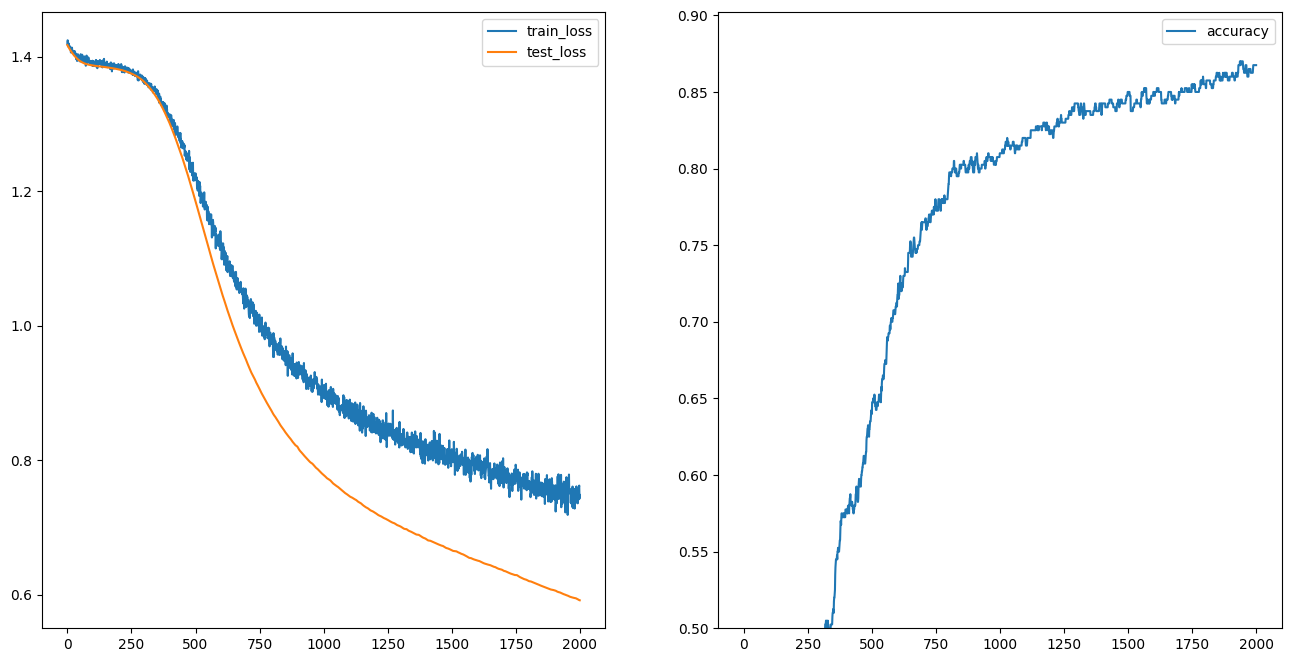

In [ ]:
# Evaluation
df_training = pd.DataFrame(result_model2['epoch_data'], 
                           columns=['epoch', 'train_loss', 'test_loss', 'accuracy']
                           )
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8))
df_training[['train_loss', 'test_loss']].plot(ax=ax1)
df_training[['accuracy']].plot(ax=ax2)

plt.ylim(bottom=0.5)
plt.show()

In [31]:
_, pred = result_model2['_, pred'] 
y_pred = pred.detach().numpy()
y_test = result_model2['actual_test_label'].detach().numpy()
pred_results = pd.DataFrame({'y_test': y_test,
                             'y_pred': y_pred})
matrix = confusion_matrix(y_test, y_pred)
matrix

array([[ 92,   0,   0,   0],
       [ 21,  75,   1,   0],
       [  0,   6,  78,  25],
       [  0,   0,   0, 102]])

In [ ]:
plt.matshow(matrix)

plt.colorbar()
plt.show()

NameError: name 'plt' is not defined

In [33]:
print('precision', precision_score(y_test, y_pred, average = 'weighted'))
print('recall', recall_score(y_test, y_pred, average = 'weighted'))
print('f1', f1_score(y_test, y_pred, average = 'weighted'))

precision 0.8856474567228703
recall 0.8675
f1 0.864071550303511


# Text Data
- ML seeks to learn the function f() that links features and target
    - autoregressive relationships: 
        - past values drive current values
        - y_t = f(x_t, y_t-1)
- Recurrent neural network is auto-regressive:
    - FFNs cannot learn from the past
    - RNNs are great at learning sequential data
    - text is sequential data
        - text classification, sentiment analysis and NLP require processing sequential stmts
        - thus RNNs are often used with text
    - in recurrent neuron: 
        - yt = output at time t
            - depends on y(t-1) and xt
        - input and output are vectors:
            - [x0, x1,...xt]
            - [y0, y1,...yt]
        - possess 'memory'
        - the stored state could be more complex than simply yt-1
        - the internal state is represented by ht, ie. hidden state in a recurrent neuron
        - each neuron has 2 weight vectors: Wx, Wy
        - yt = phi(XtWt+Yt-1Wy+b)
            - where phi is the activation function
- RNN architecture:
    - number of time periods = number of layers in the RNN
    - training also executed via gradient descent optimization
        - same mechanism as FFN
        - backpropagation through time
    - prone to vanishing or exploding gradients -> prevent convergence
        - vanishing: gradients become 0 and stops updating
        - exploding: changes widely in diff directions
    - long/short term memory cells (LSMC):
        - increase the amt of hidden state held in the neuron, eg. more than yt-1
        - which increases the memory of the neuron
        - forgot unimportant memory and form new important ones
        - peephole connections: LSTM cells that store state for more than 1 period
    - flow:
        - input + hidden -> combined
        - combined generate i2o and i2h
        - i2o and i2h combine to generate output
        - hidden state and fed back to the model's next time-instant layer
        - out combined passed to o2o -> dropout -> softmax -> output -> input(t+1)
            - output is fed back as the input at the next time instance

# Exercise - RNN Generation

In [5]:
from io import open
import glob
import os
import random
import unicodedata
import string

In [6]:
FILE_PATH = r'C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos\datasets\names\*.txt'
files = glob.glob(FILE_PATH)
df_files = pd.DataFrame(files, columns=['Files'])
pd.set_option('display.max_colwidth', 100) 
df_files

,Files
0,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
1,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
2,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
3,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
4,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
5,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
6,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
7,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
8,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...
9,C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos...


In [7]:
EOS = '/'

all_letters = string.ascii_letters + " .'" + EOS
n_letters = len(all_letters)

all_letters, n_letters

("abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ .'/", 56)

In [8]:
EOS_INDEX = n_letters - 1

EOS_INDEX

55

In [9]:
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
        and c in all_letters
    )

In [10]:
def find_files(path): 
    return glob.glob(path)

In [11]:
total_names = 0

language_names = {}

all_languages = []

for filename in find_files(FILE_PATH):
    
    language = os.path.splitext(os.path.basename(filename))[0]
    
    all_languages.append(language)
    
    names_in_file = open(filename, encoding='utf-8').read().strip().split('\n')
    
    names = [unicode_to_ascii(name) for name in names_in_file]
    
    language_names[language] = names
    
    total_names += len(names)

In [12]:
n_languages = len(all_languages)
n_languages

18

In [13]:
def letter_to_tensor(letter):
    
    tensor = torch.zeros(1, n_letters)
    tensor[0][all_letters.find(letter)] = 1
    
    return tensor

In [14]:
print(letter_to_tensor('b'))

tensor([[0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0.]])


In [15]:
def input_name_to_tensor(name):
    tensor = torch.zeros(len(name), 1, n_letters)
    
    for li, letter in enumerate(name):
        tensor[li][0][all_letters.find(letter)] = 1
    
    return tensor

In [16]:
anna_input_tensor = input_name_to_tensor('Anna')

anna_input_tensor.size()

torch.Size([4, 1, 56])

In [17]:
anna_input_tensor

tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0.]],

        [[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0

In [18]:
def target_name_to_tensor(name):
    letter_indexes = [all_letters.find(name[li]) for li in range(1, len(name))]
    
    letter_indexes.append(EOS_INDEX)
    
    return torch.LongTensor(letter_indexes)

In [19]:
target_name_to_tensor('Anna')

tensor([13, 13,  0, 55])

In [20]:
def language_to_tensor(language):
    li = all_languages.index(language)
    
    category_tensor = torch.zeros(1, n_languages)

    category_tensor[0][li] = 1
    
    return category_tensor

In [21]:
class RNN(nn.Module):
    
    def __init__(self, input_size, hidden_size, output_size):
        super(RNN, self).__init__()
        
        self.hidden_size = hidden_size

        self.i2h = nn.Linear(n_languages + input_size + hidden_size, hidden_size)
        self.i2o = nn.Linear(n_languages + input_size + hidden_size, output_size)

        self.o2o = nn.Linear(hidden_size + output_size, output_size)
        
        self.dropout = nn.Dropout(0.2)
        self.log_softmax = nn.LogSoftmax(dim=1)

    def forward(self, language, input_t, hidden):

        input_combined = torch.cat((language, input_t, hidden), 1)

        hidden = self.i2h(input_combined)
        output = self.i2o(input_combined)
        
        output_combined = torch.cat((hidden, output), 1)
        
        output = self.o2o(output_combined)
        output = self.dropout(output)

        output = self.log_softmax(output)
        
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, self.hidden_size)

In [22]:
n_hidden = 256

rnn = RNN(n_letters, n_hidden, n_letters)

In [23]:
language = language_to_tensor('English')

input_t = letter_to_tensor('S')

hidden = torch.zeros(1, n_hidden)

output, next_hidden = rnn(language, input_t, hidden)

print('output size =', output.size())
print('next_hidden size =', next_hidden.size())

output size = torch.Size([1, 56])
next_hidden size = torch.Size([1, 256])


In [24]:
def letter_from_output(output):
    
    _, top_i = output.topk(1)
    
    letter_i = top_i[0].item()
    
    return all_letters[letter_i], letter_i

In [25]:
letter_from_output(output)

('P', 41)

In [26]:
def random_training_example():
    
    random_language_index = random.randint(0, n_languages - 1)
    language = all_languages[random_language_index]
    
    random_language_names = language_names[language]
    name = random_language_names[random.randint(0, len(random_language_names) - 1)]
    
    language_tensor = language_to_tensor(language)
    
    input_name_tensor = input_name_to_tensor(name)
    target_name_tensor = target_name_to_tensor(name)
    
    print(language, name)
    
    return language_tensor, input_name_tensor, target_name_tensor

In [27]:
random_training_example()

Dutch Pender


(tensor([[0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]]),
 tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0.]],
 
         [[0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0.]],
 
         [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0.]],
 
         [[0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0

In [28]:
criterion = nn.NLLLoss()

learning_rate = 0.0005

In [29]:
def train(language_tensor, input_name_tensor, target_name_tensor):
    
    target_name_tensor.unsqueeze_(-1)
    
    hidden = rnn.initHidden()

    rnn.zero_grad()

    loss = 0

    for i in range(input_name_tensor.size(0)):
        
        output, hidden = rnn(language_tensor, input_name_tensor[i], hidden)
#         print(output.shape)
            
        l = criterion(output, target_name_tensor[i])
        
        loss += l

    loss.backward()

    for p in rnn.parameters():
        p.data.add_(-learning_rate, p.grad.data)

    return output, loss.item() / input_name_tensor.size(0)

In [30]:
n_iters = 100000
current_loss = 0
all_losses = []

In [ ]:
for iteration in range(1, n_iters + 1):
    
    language_tensor, input_name_tensor, target_name_tensor = random_training_example()
    
    output, loss = train(language_tensor, input_name_tensor, target_name_tensor)
    current_loss += loss
    
    if iteration % 5000 == 0:
        print('(%d %d%%) %.4f' % (iteration, iteration / n_iters * 100, loss))

    if iteration % 1000 == 0:
        all_losses.append(current_loss / 1000)
        current_loss = 0

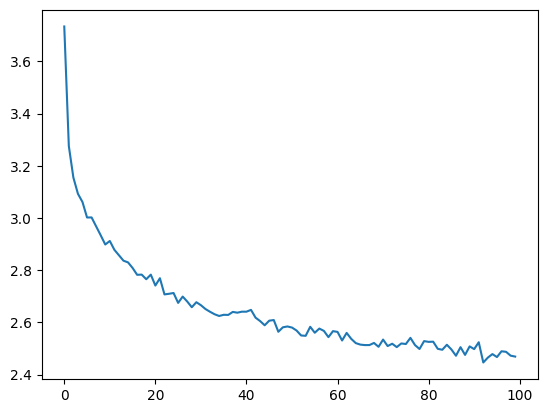

In [32]:
plt.figure()
plt.plot(all_losses)

In [33]:
MAX_LENGTH = 12

def sample(language, start_letter='A'):
    
    rnn.eval()

    with torch.no_grad():  
        language_tensor = language_to_tensor(language)
        
        input_t = input_name_to_tensor(start_letter)
        hidden = rnn.initHidden()

        output_name = start_letter

        for i in range(MAX_LENGTH):
            
            output, hidden = rnn(language_tensor, input_t[0], hidden)
            
            letter = letter_from_output(output)[0]

            if letter == EOS:
                break
            else:
                output_name += letter

            input_t = input_name_to_tensor(letter)

        return output_name

In [34]:
sample('English', 'A')

'Allen'

In [35]:
sample('French', 'F')

'Farier'

# Recommendation System 
- finding patterns in data
    - association rules learning (e.g., market basket analysis)
        - create rules rather than fit model parameters
        - eg. decision trees
        - of the form 'if x, then y'
        - use-cases: 
            - cross-selling/upselling
            - user segmentation
    - recommendation systems (e.g., which items does user like?)
    - clustering 
        - e.g., which are similar to each other, but diff from others
        - express attributes using numeric values, then group together
        - e.g., k-means clustering, hiearchial clustering
- recommendation systems
    - input: users, products, items
    - feeding into recommendation engine
    - objective: 
        - estimate the ratings that a user will assign to an item
        - then recommend the highly rated item to the user
    - approaches:
        - content-based: using user and product alone
            - explicit rating: starring system
            - implicit: view, clicks and/or purchase
            - useful for few users/items with ratings
            - requires accurate, rich product
            - tend to be domain-specific, hard to extend
        - collaborative filtering: employ info about other users and products too
            - takes into consideration aggregate of users
                - find other users like you
            - intuition: 
                - users who agreed in the past will agree in the future
                - users will like similar kinds of items as they liked in the past
            - estimate how an user would rate 'every' product
                - recommend those w/ highest ratings
            - only need user's historical preference or ratings on items
        - hybrid: combine the two
- collaborative filtering algos:
    - nearest neighbors:
        - user-based collaborative filtering
            - considered similar when two users give the same item similar ratings
        - item-based collaborative filtering
            - considered similar when items receive similar ratings from the same user
        - calculate similarities, eg cosine similarity, or euclidean
        - does not handle sparse data well, not computationally efficient or widely used
    - matrix factorization
        - output: ratings matrix w/ a score for each combination of user and product
        - technique: latent factor analysis -> find hidden features that drive ratings
            - decompose by 2 latent factor matrices
                - pick n latent factors (nf = hyperparameter)
                - user/latent factor matrix (U)
                - product/latent factor matrix (M)
                - rating (R) = dot product between the two matrices
        - Alternating least squares (ALS) algo
            - objective: 
                - estimate R matrix,
                - ie. minimize sum(rij -uimj)^2
            - steps:
                1. initialize M: assign avg rating for that product as first row
                2. fix M to solve for U using MSE
                3. fix U, solve to find M using MSE
                4. repeat until stopping criterion, eg if RMSE on training < threshold
            - use weighted regularization (WR) to prevent overfitting
                - add lambda(sum(n*u^2)+sum(n*m^2))
                - lambda is the hyperparameter for the strength of regularization
            - evaluation: Mean average precision @k
                - measures how good on avg acoss all users, the top k recos of the system were
                - steps:
                    1. for each user, find k model recos
                    2. rank by strength of recos
                    3. classify as hit or miss
                    4. calculate precision at each rank
                    4. avg precision across all ranks

# Exercise - Recommendation System

In [1]:
import torch
import torch.nn.functional as F

from torch import nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

import heapq
import math

import scipy.sparse as sp
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

In [3]:
df_rating = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\3 Predictive Analytics with PyTorch\02\demos\datasets\movies\ml-latest-small\ratings.csv")
df_rating['userId'].nunique(), df_rating['movieId'].nunique()

(610, 9724)

In [4]:
df_rating.shape

(100836, 4)

In [5]:
NUM_USERS = df_rating['userId'].max()
NUM_ITEMS = df_rating['movieId'].max()
NUM_ITEMS, NUM_USERS

(np.int64(193609), np.int64(610))

In [6]:
TEST_USER_IDS = np.random.randint(1, NUM_USERS, size=10)
TEST_USER_IDS

array([151, 170,  67, 309, 552, 364, 510, 450, 250, 345], dtype=int32)

In [7]:
test_movie_users = df_rating[df_rating['userId'].isin(TEST_USER_IDS)]
test_movie_users.shape

(705, 4)

In [8]:
def load_ratings_matrix(movie_data):

    ratings_matrix = sp.dok_matrix((NUM_USERS + 1, NUM_ITEMS + 1), dtype=np.float32)

    for index, row in movie_data.iterrows():
        user, item, rating = int(row['userId']), int(row['movieId']), float(row['rating'])
        
        ratings_matrix[user, item] = rating
    
    return ratings_matrix

In [9]:
ratings_matrix = load_ratings_matrix(df_rating)
ratings_matrix.shape

(611, 193610)

In [17]:
user_row = ratings_matrix[TEST_USER_IDS[1], :]

# Get the non-zero items as a dict
user_dict = dict(user_row.items())
print(user_dict)
# Output: {(user_id, movie_id): rating, ...}

{(0, 5): np.float32(3.0), (0, 10): np.float32(3.0), (0, 34): np.float32(5.0), (0, 48): np.float32(4.0), (0, 95): np.float32(3.0), (0, 110): np.float32(4.0), (0, 150): np.float32(3.0), (0, 153): np.float32(3.0), (0, 161): np.float32(4.0), (0, 168): np.float32(4.0), (0, 181): np.float32(3.0), (0, 185): np.float32(3.0), (0, 203): np.float32(3.0), (0, 207): np.float32(3.0), (0, 208): np.float32(4.0), (0, 266): np.float32(4.0), (0, 277): np.float32(3.0), (0, 282): np.float32(4.0), (0, 292): np.float32(3.0), (0, 296): np.float32(2.0), (0, 315): np.float32(3.0), (0, 318): np.float32(5.0), (0, 339): np.float32(4.0), (0, 344): np.float32(3.0), (0, 350): np.float32(3.0), (0, 355): np.float32(2.0), (0, 356): np.float32(4.0), (0, 364): np.float32(3.0), (0, 368): np.float32(3.0), (0, 376): np.float32(3.0), (0, 377): np.float32(4.0), (0, 410): np.float32(1.0), (0, 420): np.float32(3.0), (0, 454): np.float32(3.0), (0, 457): np.float32(3.0), (0, 480): np.float32(3.0), (0, 500): np.float32(4.0), (0, 53

In [18]:
class RecommenderNN(nn.Module):

    def __init__(self, n_users, n_items, layers=[24, 16], dropout=0.2):

        super().__init__()

        assert (layers[0] % 2 == 0), "layers[0] must be an even number"

        self.dropout = dropout

        embedding_dim = int(layers[0] / 2)

        self.user_embedding = torch.nn.Embedding(n_users, embedding_dim)
        self.item_embedding = torch.nn.Embedding(n_items, embedding_dim)

        self.fc_layers = torch.nn.ModuleList()

        for _, (in_size, out_size) in enumerate(zip(layers[:-1], layers[1:])):
            self.fc_layers.append(torch.nn.Linear(in_size, out_size))

        # Output of the last layer is just 1 for predicting ratings values
        self.output_layer = torch.nn.Linear(layers[-1], 1)

    def forward(self, users, items):
        user_embedding = self.user_embedding(users)
        item_embedding = self.item_embedding(items)

        # Concatenate user and item embeddings, this is the input to the NN
        x = torch.cat([user_embedding, item_embedding], 1)
        
        for idx, _ in enumerate(range(len(self.fc_layers))):
            x = self.fc_layers[idx](x)
            x = F.relu(x)
            x = F.dropout(x,  p=self.dropout, training=self.training)
        
        rating = self.output_layer(x)

        return rating

    def predict(self, users, items):
        output_scores = self.forward(users, items)

        return output_scores.cpu().detach().numpy()

In [19]:
def generate_training_instances(ratings_matrix):
    
    user_item_ratings = {}
    index = 0
    
    for user, item in ratings_matrix.keys():
        
        user_item_ratings[index] = (user, item, ratings_matrix[user, item])
        index += 1
    
    return user_item_ratings

In [20]:
train_user_item_ratings = generate_training_instances(ratings_matrix)

len(train_user_item_ratings)

100836

In [21]:
train_user_item_ratings[0], train_user_item_ratings[3]

((1, 1, np.float32(4.0)), (1, 47, np.float32(5.0)))

In [22]:
def train(model, train_data_loader, criterion, optimizer, epoch):
    
    model.train()
    
    epoch_loss = []
    
    for users_items_rating in train_data_loader:
        
        users, items, ratings = users_items_rating
        
        predictions = model(users, items)
        
        # Convert to float and change dim from [batch_size] to [batch_size, 1]
        ratings = ratings.float().view(predictions.size())
        
        loss = criterion(predictions, ratings)
        
        optimizer.zero_grad()
        loss.backward()
        
        optimizer.step()
        
        epoch_loss.append(loss.item())
        
    epoch_loss = np.mean(epoch_loss)

    print("Epoch completed", epoch)
    
    print("Train Loss: {%.4f}" % (epoch_loss))

In [23]:
def load_zero_rated(ratings_matrix, user_id, user_item_ratings): 
    
    for i in range(100):
        potential_zero_item = np.random.randint(1, NUM_ITEMS)
        
        while (user_id, potential_zero_item) in ratings_matrix:
            potential_zero_item = np.random.randint(1, NUM_ITEMS)
            
        user_item_ratings['users'] = \
            np.append(user_item_ratings['users'], np.array([user_id]))
        
        user_item_ratings['items'] = \
            np.append(user_item_ratings['items'], np.array([potential_zero_item]))
        
        user_item_ratings['ratings'] = \
            np.append(user_item_ratings['ratings'], np.array([0]))

In [24]:
def generate_test_instances(ratings_matrix, test_movie_users):

    test_list = []

    for user_id in TEST_USER_IDS:
        
        user_item_ratings_df = test_movie_users[test_movie_users['userId'] == user_id]
        user_item_ratings_df = user_item_ratings_df[user_item_ratings_df['rating'] >= 4]
        
        user_item_ratings = {}
        
        user_item_ratings['users'] = user_item_ratings_df['userId'].values[5:15]
        user_item_ratings['items'] = user_item_ratings_df['movieId'].values[5:15]
        user_item_ratings['ratings'] = user_item_ratings_df['rating'].values[5:15]
        
        load_zero_rated(ratings_matrix, user_id, user_item_ratings)
        
        test_list.append(user_item_ratings)
        
    return test_list

In [25]:
test_list = generate_test_instances(ratings_matrix, test_movie_users)

len(test_list)

10

In [26]:
test_list[1]

{'users': array([170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170, 170,
        170, 170, 170, 170, 170, 170]),
 'items': array([   208,    266,    282,    318,    339,    356,    377,    500,
           539,    553, 142302,  87866, 107636, 122404, 150749,  84265,
        190988,   9118,  37063, 188119, 173931,  49933,  84233,  42861,
        133592,  51048,   4058,  51396,   6445, 148775, 142187,  16791,
         46420,  83749,  85284,  81075,  84192, 105563,  55479,  15462

In [27]:
def apk(actual, predicted, k=10):
    """
    Average Precision at K
    actual: list of actual relevant items
    predicted: list of predicted items (in order of relevance)
    k: number of predictions to consider
    """
    if not actual:
        return 0.0
    
    if len(predicted) > k:
        predicted = predicted[:k]
    
    score = 0.0
    num_hits = 0.0
    
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            num_hits += 1.0
            score += num_hits / (i + 1.0)
    
    return score / min(len(actual), k)

def mapk(actual_list, predicted_list, k=10):
    """Mean Average Precision at K"""
    return np.mean([apk(a, p, k) for a, p in zip(actual_list, predicted_list)])

def evaluate(model, test_list):

    model.eval()
    
    apks = []

    for user_item_ratings in test_list:
        
        users = torch.tensor(user_item_ratings['users'])
        items = torch.tensor(user_item_ratings['items'])
        ratings = user_item_ratings['ratings']

        predictions = model.predict(users, items)
        
        item_score_map = {}
        
        for i, item in enumerate(user_item_ratings['items']):
            item_score_map[item] = predictions[i]
        
        rank_list = heapq.nlargest(100, item_score_map, key=item_score_map.get)
        
        items_list = items.detach().numpy().tolist()
        rank_list = list(rank_list)

        apk_score = apk(items_list[:10], rank_list[:10])
        
        apks.append(apk_score)
        
    
    print("Evaluation mean APK : {%.4f}" % np.mean(apks))

In [31]:
model = RecommenderNN(NUM_USERS + 1, NUM_ITEMS + 1, [32, 16, 8], dropout=0.2)

criterion = torch.nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.00001)

num_epochs = 8

In [29]:
train_data_loader = DataLoader(
    train_user_item_ratings, batch_size=100, shuffle=True, num_workers=0)

In [32]:
for epoch in range(1, num_epochs + 1):
    
    train(model, train_data_loader, criterion, optimizer, epoch)
    evaluate(model, test_list)

Epoch completed 1
Train Loss: {2.5848}
Evaluation mean APK : {0.4116}
Epoch completed 2
Train Loss: {1.4744}
Evaluation mean APK : {0.6575}
Epoch completed 3
Train Loss: {1.2802}
Evaluation mean APK : {0.6619}
Epoch completed 4
Train Loss: {1.1373}
Evaluation mean APK : {0.7382}
Epoch completed 5
Train Loss: {1.0196}
Evaluation mean APK : {0.7829}
Epoch completed 6
Train Loss: {0.9299}
Evaluation mean APK : {0.7904}
Epoch completed 7
Train Loss: {0.8680}
Evaluation mean APK : {0.8030}
Epoch completed 8
Train Loss: {0.8222}
Evaluation mean APK : {0.8139}
